In [3]:
# =============================================================================
# PROYECTO: Modelado Estadístico del Desgaste Laboral (Burnout)
# Autor: Grupo 8
# Herramientas: R / RStudio / R Markdown
# =============================================================================

# -----------------------------------------------------------------------------
# 0. CONFIGURACIÓN INICIAL
# -----------------------------------------------------------------------------

# Instalación de librerías necesarias si no están instaladas
paquetes <- c("Hmisc", "lmtest", "car", "MASS", "corrplot", "ppcor", "olsrr", "knitr", "dplyr", "ggplot2", "GGally")
nuevos_paquetes <- paquetes[!(paquetes %in% installed.packages()[, "Package"])]
if(length(nuevos_paquetes)) install.packages(nuevos_paquetes, repos = "https://cloud.r-project.org")

# Librerías necesarias
library(Hmisc)      # rcorr: matriz de correlaciones con p-valores
library(lmtest)     # bptest: homocedasticidad
library(car)        # vif, outlierTest, leveragePlots
library(MASS)       # boxcox
library(corrplot)   # visualización de correlaciones
library(ppcor)      # correlaciones parciales
library(olsrr)      # ols_step_all_possible
library(knitr)      # kable: tablas limpias
library(dplyr)      # manipulación de datos
library(ggplot2)    # gráficos con estética limpia
library(GGally)     # ggpairs: matriz de dispersión mejorada

# Carga del dataset
datos <- read.csv("burnout_tp.csv", sep = ",")

# Semilla reproducible (número de grupo = 8)
set.seed(8)

# Muestra aleatoria de n = 35
n <- 35
muestra <- sample(1:nrow(datos), size = n, replace = FALSE)
datos_muestra <- datos[muestra, ]

# Inspección inicial
head(datos_muestra)
str(datos_muestra)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘fracdiff’, ‘timeDate’, ‘urca’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘checkmate’, ‘numDeriv’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘patchwork’, ‘gridExtra’, ‘htmlTable’, ‘colorspace’, ‘Formula’, ‘zoo’, ‘carData’, ‘abind’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘goftest’, ‘nortest’, ‘xplorerr’, ‘ggstats’



Attaching package: ‘Hmisc’


The following objects are masked from ‘package:base’:

    format.pval, units


Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric


Loading required package: carData

corrplot 0.95 loaded


Attaching package: ‘olsrr’


The following object is masked from ‘package:MASS’:

    cement


The following object is masked from ‘package:datasets’:

    rivers



Attaching package: ‘dplyr

,Burnout_Score,Anxiety_Score,Depression_Score,Work_Hours_Per_Week,Sleep_Hours,Screen_Time_Hours
,<int>,<int>,<int>,<int>,<dbl>,<dbl>
13620,0,7,4,27,8.6,3.2
42722,22,37,42,64,9.7,5.8
42238,38,19,35,65,4.4,3.1
5853,27,30,12,46,7.4,6.9
35715,21,25,16,43,4.6,11.8
17332,21,10,7,32,7.5,5.7


'data.frame':	35 obs. of  6 variables:
 $ Burnout_Score      : int  0 22 38 27 21 21 42 19 24 51 ...
 $ Anxiety_Score      : int  7 37 19 30 25 10 25 34 43 46 ...
 $ Depression_Score   : int  4 42 35 12 16 7 41 15 26 31 ...
 $ Work_Hours_Per_Week: int  27 64 65 46 43 32 30 36 59 32 ...
 $ Sleep_Hours        : num  8.6 9.7 4.4 7.4 4.6 7.5 6.4 7.8 8.9 7.7 ...
 $ Screen_Time_Hours  : num  3.2 5.8 3.1 6.9 11.8 5.7 7.7 2.5 8.4 10.1 ...




Table: Estadísticos descriptivos de las variables cuantitativas

|                    |  Media| Mediana|     DE|  Min|  Max| Asimetria| Curtosis|
|:-------------------|------:|-------:|------:|----:|----:|---------:|--------:|
|Burnout_Score       | 38.029|    35.0| 21.537|  0.0| 78.0|     0.222|   -0.978|
|Anxiety_Score       | 39.000|    37.0| 23.983|  0.0| 86.0|     0.174|   -1.021|
|Depression_Score    | 38.171|    41.0| 22.911|  1.0| 88.0|     0.206|   -1.013|
|Work_Hours_Per_Week | 47.257|    46.0| 15.195| 20.0| 70.0|    -0.062|   -1.443|
|Sleep_Hours         |  7.063|     7.4|  1.872|  4.3|  9.7|    -0.147|   -1.495|
|Screen_Time_Hours   |  8.286|     8.0|  3.547|  2.0| 14.0|    -0.085|   -1.253|



Table: Matriz de correlaciones de Pearson (r)

|                    | Burnout_Score| Anxiety_Score| Depression_Score| Work_Hours_Per_Week| Sleep_Hours| Screen_Time_Hours|
|:-------------------|-------------:|-------------:|----------------:|-------------------:|-----------:|-----------------:|
|Burnout_Score       |         1.000|         0.883|            0.902|               0.453|      -0.263|             0.224|
|Anxiety_Score       |         0.883|         1.000|            0.876|               0.507|      -0.269|             0.167|
|Depression_Score    |         0.902|         0.876|            1.000|               0.531|      -0.292|             0.197|
|Work_Hours_Per_Week |         0.453|         0.507|            0.531|               1.000|      -0.122|             0.053|
|Sleep_Hours         |        -0.263|        -0.269|           -0.292|              -0.122|       1.000|             0.164|
|Screen_Time_Hours   |         0.224|         0.167|            0.197|             



Table: p-valores asociados a cada correlación

|                    | Burnout_Score| Anxiety_Score| Depression_Score| Work_Hours_Per_Week| Sleep_Hours| Screen_Time_Hours|
|:-------------------|-------------:|-------------:|----------------:|-------------------:|-----------:|-----------------:|
|Burnout_Score       |            NA|        0.0000|           0.0000|              0.0063|      0.1264|            0.1963|
|Anxiety_Score       |        0.0000|            NA|           0.0000|              0.0019|      0.1179|            0.3387|
|Depression_Score    |        0.0000|        0.0000|               NA|              0.0010|      0.0893|            0.2558|
|Work_Hours_Per_Week |        0.0063|        0.0019|           0.0010|                  NA|      0.4860|            0.7628|
|Sleep_Hours         |        0.1264|        0.1179|           0.0893|              0.4860|          NA|            0.3474|
|Screen_Time_Hours   |        0.1963|        0.3387|           0.2558|             



Table: Correlación del Burnout_Score con cada predictor

|                    |Variable            |       r| p_valor|
|:-------------------|:-------------------|-------:|-------:|
|Anxiety_Score       |Anxiety_Score       |  0.8833|  0.0000|
|Depression_Score    |Depression_Score    |  0.9025|  0.0000|
|Work_Hours_Per_Week |Work_Hours_Per_Week |  0.4531|  0.0063|
|Sleep_Hours         |Sleep_Hours         | -0.2634|  0.1264|
|Screen_Time_Hours   |Screen_Time_Hours   |  0.2238|  0.1963|


	Pearson's product-moment correlation

data:  datos_muestra$Burnout_Score and datos_muestra$Depression_Score
t = 12.036, df = 33, p-value = 1.288e-13
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.8140631 0.9500126
sample estimates:
      cor 
0.9024812 



	Pearson's product-moment correlation

data:  datos_muestra$Burnout_Score and datos_muestra$Anxiety_Score
t = 10.826, df = 33, p-value = 2.141e-12
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.7795729 0.9399049
sample estimates:
      cor 
0.8833373 


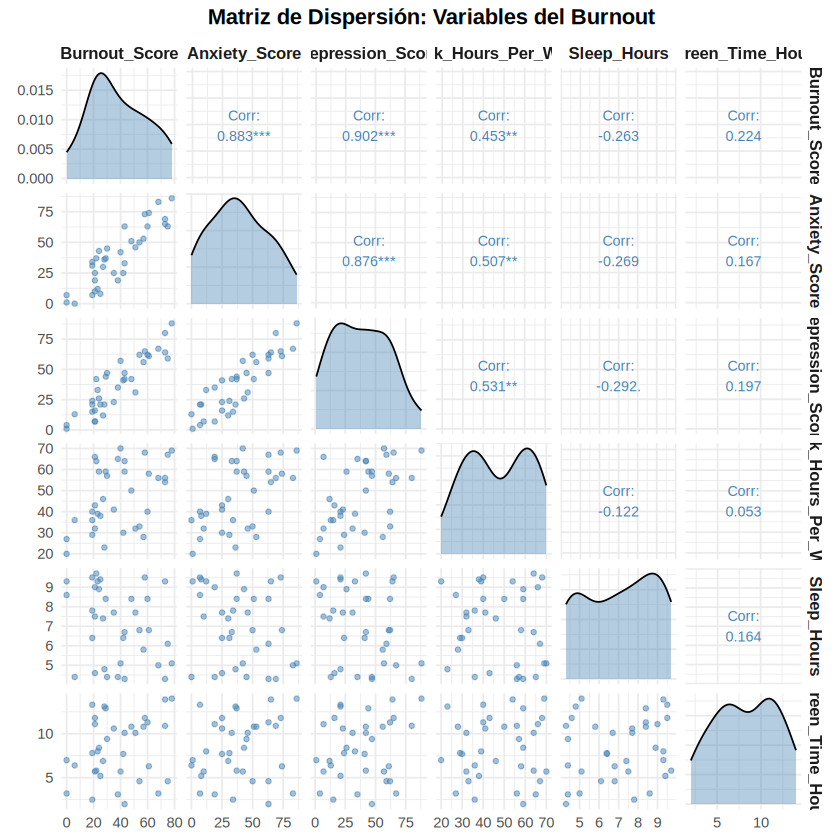

In [8]:
# =============================================================================
# FASE 1: ANÁLISIS EXPLORATORIO Y CORRELACIÓN (Base del TEI 1)
# =============================================================================

# --- 1.1 Estadísticos descriptivos -------------------------------------------

# Resumen de tendencia central, dispersión y forma para variables cuantitativas
vars_cuant <- datos_muestra %>%
  select(Burnout_Score, Anxiety_Score, Depression_Score,
         Work_Hours_Per_Week, Sleep_Hours, Screen_Time_Hours)

# Tabla descriptiva completa
descriptivos <- data.frame(
  Variable = names(vars_cuant),
  Media    = sapply(vars_cuant, mean, na.rm = TRUE),
  Mediana  = sapply(vars_cuant, median, na.rm = TRUE),
  DE       = sapply(vars_cuant, sd, na.rm = TRUE),
  Min      = sapply(vars_cuant, min, na.rm = TRUE),
  Max      = sapply(vars_cuant, max, na.rm = TRUE),
  Asimetria = sapply(vars_cuant, function(x) {
    n <- length(x); sum((x - mean(x))^3) / (n * sd(x)^3)
  }),
  Curtosis = sapply(vars_cuant, function(x) {
    n <- length(x); sum((x - mean(x))^4) / (n * sd(x)^4) - 3
  })
)
kable(round(descriptivos[, -1], 3),
      caption = "Estadísticos descriptivos de las variables cuantitativas")

# --- 1.2 Matriz de dispersión (estética limpia) ------------------------------

# ggpairs: matriz de dispersión con correlaciones y densidades
ggpairs(vars_cuant,
        title = "Matriz de Dispersión: Variables del Burnout",
        upper = list(continuous = wrap("cor", size = 3, color = "steelblue")),
        lower = list(continuous = wrap("points", alpha = 0.5, size = 1.2,
                                        color = "steelblue")),
        diag  = list(continuous = wrap("densityDiag", fill = "steelblue",
                                        alpha = 0.4))) +
  theme_minimal(base_size = 11) +
  theme(strip.text = element_text(face = "bold", size = 10),
        plot.title = element_text(face = "bold", hjust = 0.5))

# --- 1.3 Matriz de correlaciones con test de hipótesis -----------------------

matriz_cor <- rcorr(as.matrix(vars_cuant), type = "pearson")

# Matriz de coeficientes r
kable(round(matriz_cor$r, 3),
      caption = "Matriz de correlaciones de Pearson (r)")

# Matriz de p-valores
kable(round(matriz_cor$P, 4),
      caption = "p-valores asociados a cada correlación")

# Correlación específica Burnout vs. predictores
cor_burnout <- data.frame(
  Variable = c("Anxiety_Score", "Depression_Score",
               "Work_Hours_Per_Week", "Sleep_Hours", "Screen_Time_Hours"),
  r        = sapply(vars_cuant[, -1], function(x) cor(vars_cuant$Burnout_Score, x)),
  p_valor  = sapply(vars_cuant[, -1], function(x)
    cor.test(vars_cuant$Burnout_Score, x)$p.value)
)

# Solución: Redondear únicamente las columnas numéricas (columnas 2 y 3)
cor_burnout_redondeado <- cor_burnout
cor_burnout_redondeado[, -1] <- round(cor_burnout[, -1], 4)

kable(cor_burnout_redondeado,
      caption = "Correlación del Burnout_Score con cada predictor")

# Test formal de correlación (el más fuerte: Depression_Score)
cor.test(datos_muestra$Burnout_Score, datos_muestra$Depression_Score)
cor.test(datos_muestra$Burnout_Score, datos_muestra$Anxiety_Score)

# CONCLUSIÓN FASE 1:
# Las variables con evidencia de relación lineal fuerte con Burnout_Score
# son Depression_Score (r = 0.90) y Anxiety_Score (r = 0.88).
# Work_Hours_Per_Week muestra una relación moderada (r = 0.45).
# Sleep_Hours y Screen_Time_Hours no superan el umbral de asociación relevante.


Call:
lm(formula = Burnout_Score ~ Depression_Score, data = datos_muestra)

Residuals:
    Min      1Q  Median      3Q     Max 
-19.277  -5.477   1.539   5.027  19.301 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)       5.64509    3.12603   1.806   0.0801 .  
Depression_Score  0.84837    0.07048  12.036 1.29e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 9.416 on 33 degrees of freedom
Multiple R-squared:  0.8145,	Adjusted R-squared:  0.8089 
F-statistic: 144.9 on 1 and 33 DF,  p-value: 1.288e-13


Ecuación estimada: Burnout_Score = 5.6451 + 0.8484 * Depression_Score




Table: Intervalos de confianza al 99% para los parámetros

|                 |   0.5 %|  99.5 %|
|:----------------|-------:|-------:|
|(Intercept)      | -2.8992| 14.1894|
|Depression_Score |  0.6557|  1.0410|

Estadístico t = 12.0362 | p-valor unilateral = 0 




Table: Tabla ANOVA del modelo simple

|                 | Df|    Sum Sq|     Mean Sq| F value| Pr(>F)|
|:----------------|--:|---------:|-----------:|-------:|------:|
|Depression_Score |  1| 12845.019| 12845.01915| 144.871|      0|
|Residuals        | 33|  2925.952|    88.66522|      NA|     NA|

R² ajustado = 0.8089 



	Shapiro-Wilk normality test

data:  re_simple
W = 0.98515, p-value = 0.9075


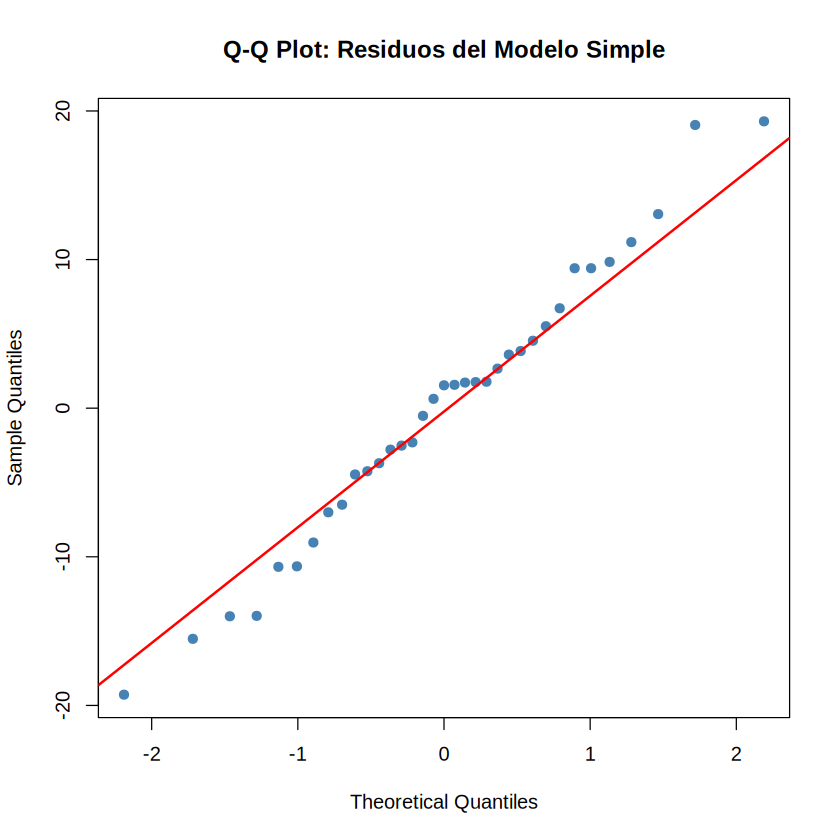


	studentized Breusch-Pagan test

data:  modelo_simple
BP = 0.0033013, df = 1, p-value = 0.9542


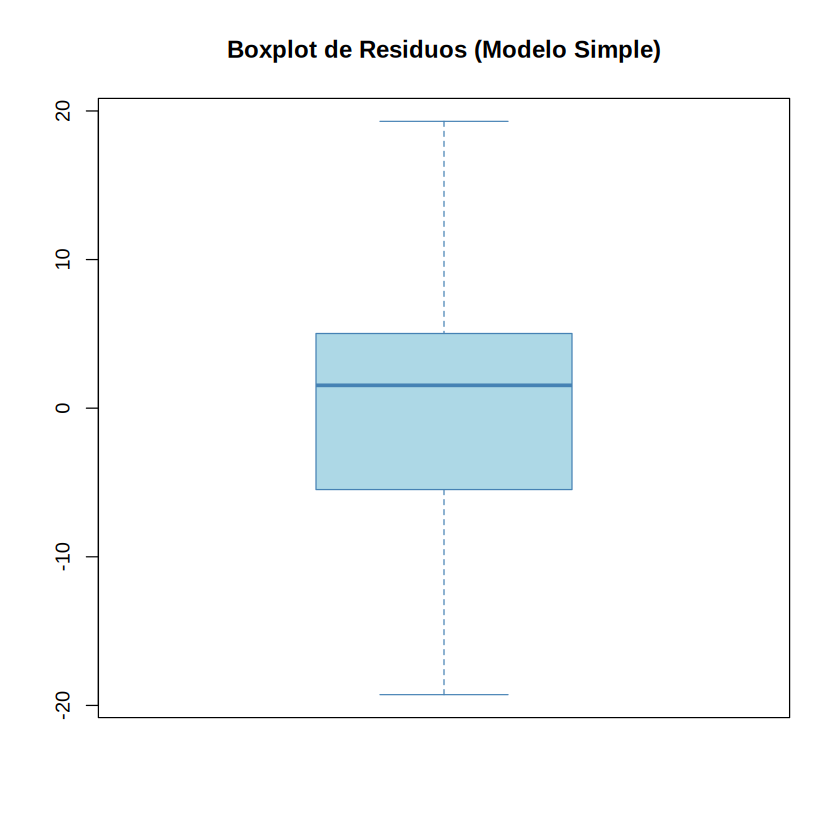


	Durbin-Watson test

data:  modelo_simple
DW = 1.8847, p-value = 0.3509
alternative hypothesis: true autocorrelation is greater than 0


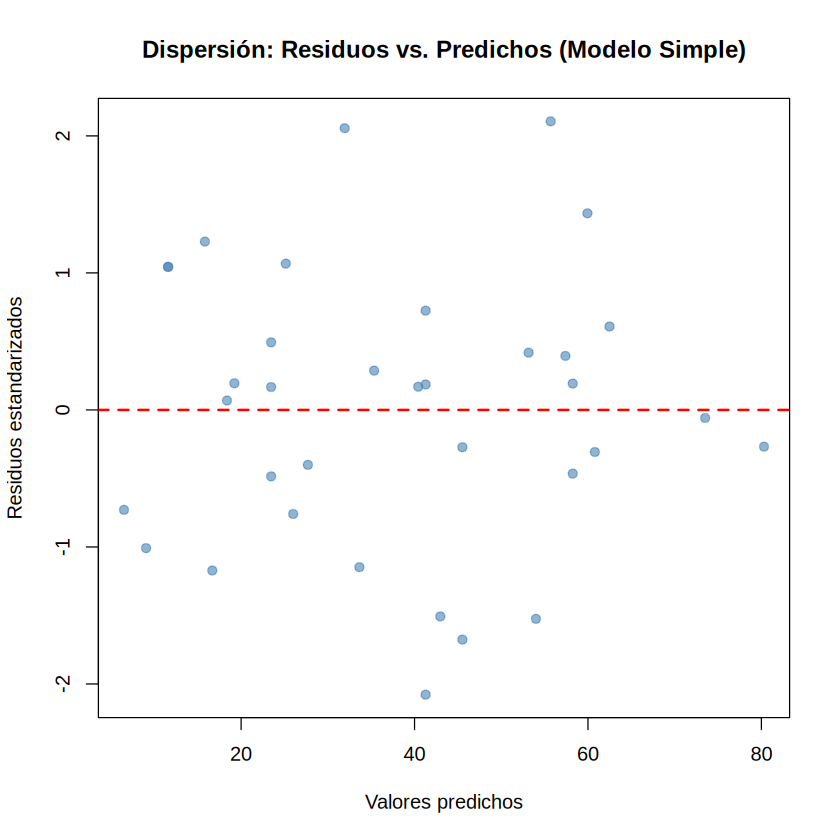

In [5]:
# =============================================================================
# FASE 2: MODELADO SIMPLE Y SUPUESTOS (Cierre del TEI 1)
# =============================================================================

# --- 2.1 Ajuste del modelo de RLS --------------------------------------------

# Variable respuesta: Burnout_Score | Predictor más fuerte: Depression_Score
modelo_simple <- lm(Burnout_Score ~ Depression_Score, data = datos_muestra)
summary(modelo_simple)

# Ecuación de la recta
cat("Ecuación estimada: Burnout_Score =",
    round(coef(modelo_simple)[1], 4), "+",
    round(coef(modelo_simple)[2], 4), "* Depression_Score\n")

# --- 2.2 Interpretación de coeficientes --------------------------------------

# b0 (intercepto): valor promedio esperado del Burnout cuando Depression = 0
# b1 (pendiente): incremento promedio del Burnout por cada punto adicional
#                 en Depression_Score

# --- 2.3 Intervalos de confianza al 99% --------------------------------------

ic_99 <- confint(modelo_simple, level = 0.99)
kable(round(ic_99, 4),
      caption = "Intervalos de confianza al 99% para los parámetros")

# --- 2.4 Test de nulidad (H0: beta_j = 0) ------------------------------------

# Ya se observa en summary(): p-valor < 0.001 -> se rechaza H0.
# La pendiente es estadísticamente distinta de cero.

# --- 2.5 Test de hipótesis para pendiente POSITIVA (unilateral) --------------

# H0: beta1 <= 0  vs  H1: beta1 > 0
resumen_simple <- summary(modelo_simple)
t_obs <- resumen_simple$coefficients[2, "t value"]
p_unilateral <- pt(t_obs, df = modelo_simple$df.residual, lower.tail = FALSE)
cat("Estadístico t =", round(t_obs, 4),
    "| p-valor unilateral =", format.pval(p_unilateral, digits = 4), "\n")

# --- 2.6 ANOVA y coeficiente de determinación --------------------------------

anova_simple <- anova(modelo_simple)
kable(anova_simple, caption = "Tabla ANOVA del modelo simple")

r2_ajustado <- resumen_simple$adj.r.squared
cat("R² ajustado =", round(r2_ajustado, 4), "\n")

# --- 2.7 Diagnóstico de supuestos --------------------------------------------

# Residuos y predichos
re_simple  <- residuals(modelo_simple)
pre_simple <- fitted(modelo_simple)
zre_simple <- rstandard(modelo_simple)

# Normalidad
shapiro.test(re_simple)

# Q-Q plot con estética limpia
qqnorm(re_simple, main = "Q-Q Plot: Residuos del Modelo Simple",
       pch = 19, col = "steelblue")
qqline(re_simple, col = "red", lwd = 2)

# Boxplot de residuos
boxplot(re_simple, main = "Boxplot de Residuos (Modelo Simple)",
        col = "lightblue", border = "steelblue")

# Homocedasticidad (Breusch-Pagan)
bptest(modelo_simple)

# Dispersión de residuos estandarizados vs. predichos
plot(pre_simple, zre_simple,
     xlab = "Valores predichos", ylab = "Residuos estandarizados",
     main = "Dispersión: Residuos vs. Predichos (Modelo Simple)",
     pch = 19, col = adjustcolor("steelblue", alpha.f = 0.6))
abline(h = 0, col = "red", lwd = 2, lty = 2)

# Independencia (Durbin-Watson)
dwtest(modelo_simple)

# CONCLUSIÓN FASE 2:
# El modelo simple cumple los supuestos (normalidad, homocedasticidad,
# independencia). El R² ajustado ≈ 0.80 indica que Depression_Score explica
# aproximadamente el 80% de la variabilidad del Burnout. Es un buen modelo,
# pero puede mejorarse incorporando Anxiety_Score.

In [9]:
# =============================================================================
# FASE 3: MODELADO MÚLTIPLE Y MULTICOLINEALIDAD (Inicio del TEI 2)
# =============================================================================

# --- 3.1 Ajuste del modelo de RLM --------------------------------------------

# Predictores: Anxiety_Score, Depression_Score, Work_Hours_Per_Week
modelo_multiple <- lm(Burnout_Score ~ Anxiety_Score + Depression_Score +
                        Work_Hours_Per_Week, data = datos_muestra)
summary(modelo_multiple)

# Ecuación del modelo
cat("Ecuación estimada:\n")
cat("Burnout_Score =",
    round(coef(modelo_multiple)[1], 4), "+",
    round(coef(modelo_multiple)[2], 4), "* Anxiety_Score +",
    round(coef(modelo_multiple)[3], 4), "* Depression_Score +",
    round(coef(modelo_multiple)[4], 4), "* Work_Hours_Per_Week\n")

# --- 3.2 Interpretación de coeficientes --------------------------------------

# b0: valor esperado del Burnout cuando todos los predictores son 0
# b1 (Anxiety): efecto de la ansiedad manteniendo constante depresión y horas
# b2 (Depression): efecto de la depresión manteniendo constante ansiedad y horas
# b3 (Work_Hours): efecto de las horas de trabajo manteniendo constante
#                  ansiedad y depresión

# --- 3.3 Intervalos de confianza al 95% --------------------------------------

ic_multiple <- confint(modelo_multiple, level = 0.95)
kable(round(ic_multiple, 4),
      caption = "Intervalos de confianza al 95% para los parámetros (RLM)")

# --- 3.4 Test de nulidad individual y prueba F global ------------------------

# Test de nulidad individual: se observa en summary()
# Prueba F de significación global
cat("F-statistic:", summary(modelo_multiple)$fstatistic[1],
    "| p-valor:", format.pval(summary(modelo_multiple)$fstatistic[3],
                               digits = 4), "\n")
cat("R² ajustado =", round(summary(modelo_multiple)$adj.r.squared, 4), "\n")

# --- 3.5 Diagnóstico de multicolinealidad (VIF) ------------------------------

vif_multiple <- vif(modelo_multiple)
kable(round(vif_multiple, 4),
      caption = "VIF del modelo con tres predictores")

# Regla: VIF > 10 indica multicolinealidad severa.
# Anxiety y Depression presentan VIF ≈ 4.3-4.5 (moderado).
# Work_Hours tiene VIF ≈ 1.4 (sin problemas).

# --- 3.6 Reajuste eliminando la variable menos significativa -----------------

# Se elimina Work_Hours_Per_Week por:
#   (a) no ser significativa (p = 0.466)
#   (b) evitar redundancia en el modelo
modelo_reducido <- lm(Burnout_Score ~ Anxiety_Score + Depression_Score,
                      data = datos_muestra)
summary(modelo_reducido)

# VIF del modelo reducido
vif_reducido <- vif(modelo_reducido)
kable(round(vif_reducido, 4),
      caption = "VIF del modelo reducido (sin Work_Hours)")


Call:
lm(formula = Burnout_Score ~ Anxiety_Score + Depression_Score + 
    Work_Hours_Per_Week, data = datos_muestra)

Residuals:
    Min      1Q  Median      3Q     Max 
-15.940  -5.931  -1.076   6.433  18.549 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)    
(Intercept)          7.04180    4.81982   1.461 0.154076    
Anxiety_Score        0.36809    0.12813   2.873 0.007282 ** 
Depression_Score     0.54094    0.13647   3.964 0.000404 ***
Work_Hours_Per_Week -0.08501    0.11529  -0.737 0.466468    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.612 on 31 degrees of freedom
Multiple R-squared:  0.8542,	Adjusted R-squared:  0.8401 
F-statistic: 60.55 on 3 and 31 DF,  p-value: 4.606e-13


Ecuación estimada:
Burnout_Score = 7.0418 + 0.3681 * Anxiety_Score + 0.5409 * Depression_Score + -0.085 * Work_Hours_Per_Week




Table: Intervalos de confianza al 95% para los parámetros (RLM)

|                    |   2.5 %|  97.5 %|
|:-------------------|-------:|-------:|
|(Intercept)         | -2.7883| 16.8719|
|Anxiety_Score       |  0.1068|  0.6294|
|Depression_Score    |  0.2626|  0.8193|
|Work_Hours_Per_Week | -0.3201|  0.1501|

F-statistic: 60.54905 | p-valor: 31 
R² ajustado = 0.8401 




Table: VIF del modelo con tres predictores

|                    |      x|
|:-------------------|------:|
|Anxiety_Score       | 4.3293|
|Depression_Score    | 4.4814|
|Work_Hours_Per_Week | 1.4070|


Call:
lm(formula = Burnout_Score ~ Anxiety_Score + Depression_Score, 
    data = datos_muestra)

Residuals:
     Min       1Q   Median       3Q      Max 
-17.3019  -5.6768  -0.3586   6.0735  17.5409 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)        4.2057     2.8837   1.458 0.154459    
Anxiety_Score      0.3585     0.1266   2.832 0.007927 ** 
Depression_Score   0.5198     0.1325   3.924 0.000433 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 8.55 on 32 degrees of freedom
Multiple R-squared:  0.8517,	Adjusted R-squared:  0.8424 
F-statistic: 91.86 on 2 and 32 DF,  p-value: 5.496e-14




Table: VIF del modelo reducido (sin Work_Hours)

|                 |      x|
|:----------------|------:|
|Anxiety_Score    | 4.2843|
|Depression_Score | 4.2843|

  Index N                                         Predictors  R-Square
2     1 1                                   Depression_Score 0.8144723
1     2 1                                      Anxiety_Score 0.7802847
3     3 1                                Work_Hours_Per_Week 0.2053030
4     4 2                     Anxiety_Score Depression_Score 0.8516620
6     5 2               Depression_Score Work_Hours_Per_Week 0.8154112
5     6 2                  Anxiety_Score Work_Hours_Per_Week 0.7803282
7     7 3 Anxiety_Score Depression_Score Work_Hours_Per_Week 0.8542186
  Adj. R-Square Mallow's Cp
2     0.8088502    8.451941
1     0.7736267   15.721826
3     0.1812213  137.990053
4     0.8423909    2.543650
6     0.8038744   10.252281
5     0.7665987   17.712587
7     0.8401107    4.000000




Table: Todos los subconjuntos posibles: métricas comparativas

|   | mindex|  n|predictors                                         |   rsquare|      adjr|      rmse|   predrsq|         cp|      aic|     sbic|      sbc|      msep|       fpe|       apc|       hsp|
|:--|------:|--:|:--------------------------------------------------|---------:|---------:|---------:|---------:|----------:|--------:|--------:|--------:|---------:|---------:|---------:|---------:|
|2  |      1|  1|Depression_Score                                   | 0.8144723| 0.8088502|  9.143229| 0.7951346|   8.451941| 260.2366| 160.4341| 264.9027|  3103.599|  93.73180| 0.2080159|  2.770788|
|1  |      2|  1|Anxiety_Score                                      | 0.7802847| 0.7736267|  9.950051| 0.7565100|  15.721826| 266.1561| 165.7010| 270.8222|  3675.506| 111.00395| 0.2463474|  3.281367|
|3  |      3|  1|Work_Hours_Per_Week                                | 0.2053030| 0.1812213| 18.923261| 0.1015871| 137.990053| 311.1531|

NULL


	Shapiro-Wilk normality test

data:  re_final
W = 0.99028, p-value = 0.9865


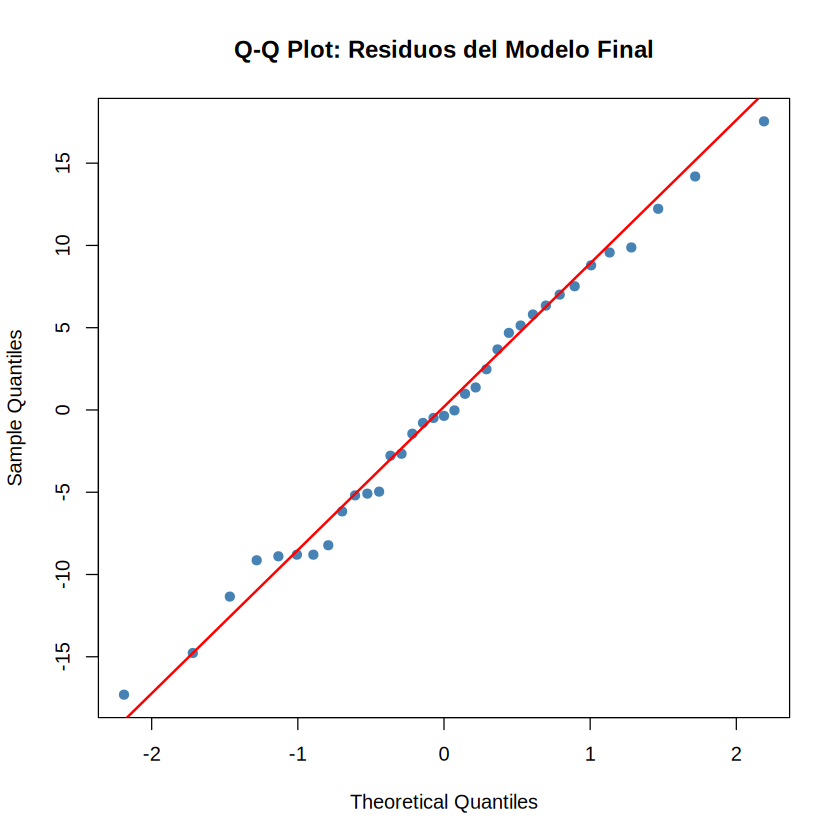


	studentized Breusch-Pagan test

data:  modelo_reducido
BP = 0.081939, df = 2, p-value = 0.9599


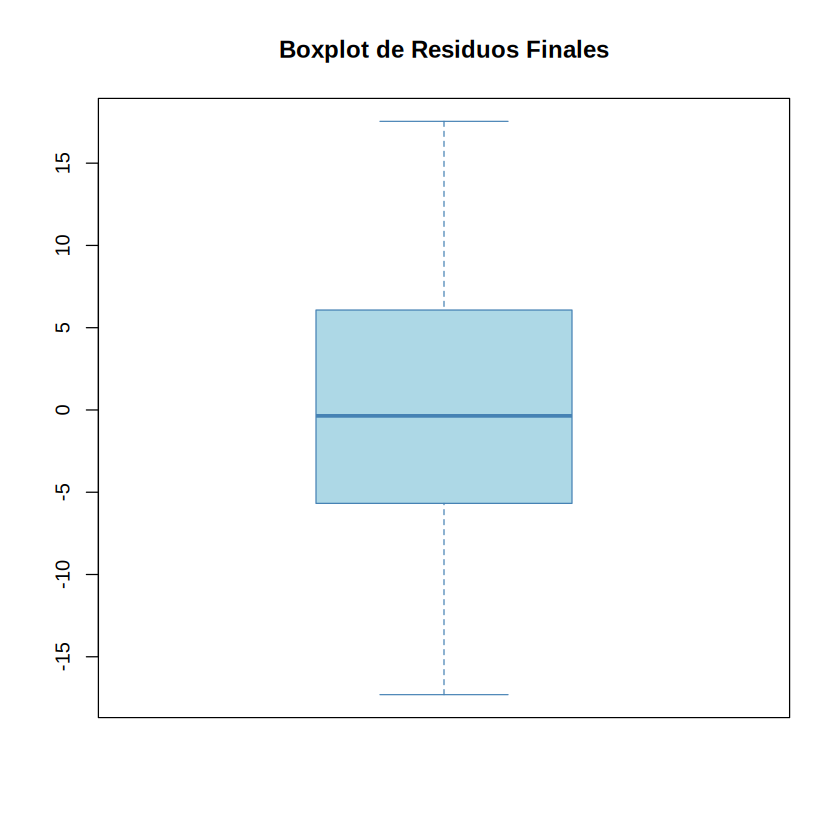


	Durbin-Watson test

data:  modelo_reducido
DW = 2.0003, p-value = 0.479
alternative hypothesis: true autocorrelation is greater than 0


Observaciones con alto leverage:  
Observaciones influyentes (Cook):  




Table: Tabla de coincidencia de registros anómalos

| Fila|Es_Leverage_X |Es_Influencia_Cook |Es_Outlier_Y | Cant_Coincidencias|
|----:|:-------------|:------------------|:------------|------------------:|

ERROR: Error in boxcox.default(modelo_reducido, lambda = seq(-2, 2, by = 0.1)): response variable must be positive


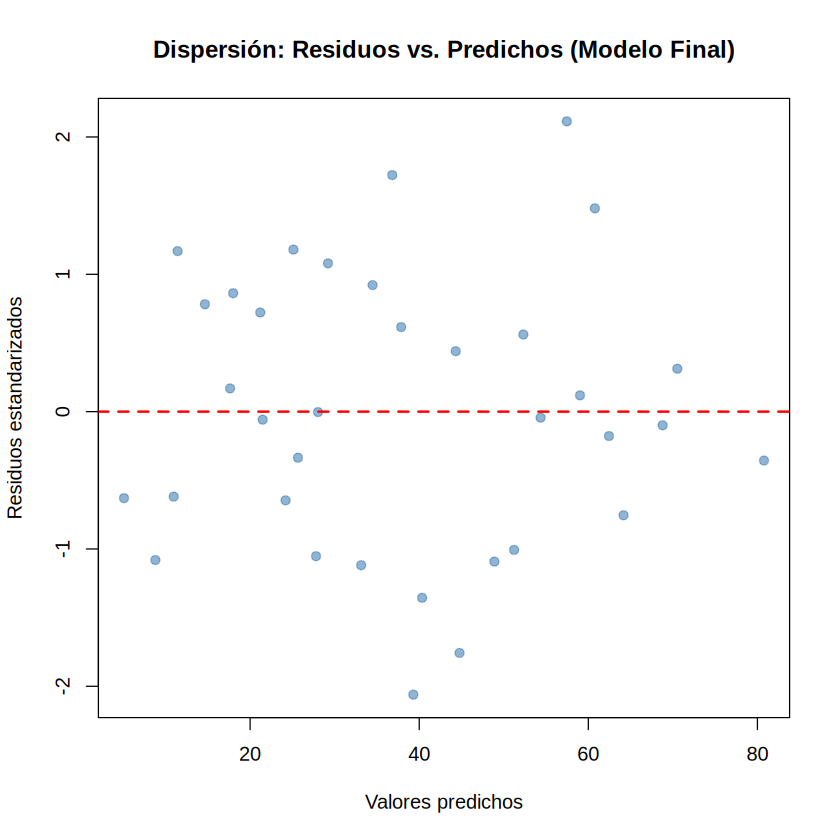

In [11]:
# =============================================================================
# FASE 4: SELECCIÓN DE VARIABLES Y DIAGNÓSTICO AVANZADO (Cierre del TEI 2)
# =============================================================================

# --- 4.1 Selección de variables: Todos los Subconjuntos Posibles -------------

subconjuntos <- ols_step_all_possible(modelo_multiple)
print(subconjuntos)

# Tabla comparativa de métricas
kable(subconjuntos$result,
      caption = "Todos los subconjuntos posibles: métricas comparativas")

# Gráfico comparativo con estética limpia
plot(subconjuntos) +
  theme_minimal(base_size = 11) +
  theme(plot.title = element_text(face = "bold", hjust = 0.5))

# CONCLUSIÓN: El modelo 4 (Anxiety + Depression) presenta:
#   - Mayor R² ajustado (0.8423)
#   - Menor Cp de Mallows (2.54)
#   - Menor AIC y SBIC
# Por lo tanto, es el modelo final.

# --- 4.2 Verificación de supuestos del modelo final --------------------------

re_final  <- residuals(modelo_reducido)
pre_final <- fitted(modelo_reducido)
zre_final <- rstandard(modelo_reducido)

# Normalidad
shapiro.test(re_final)

# Q-Q plot
qqnorm(re_final, main = "Q-Q Plot: Residuos del Modelo Final",
       pch = 19, col = "steelblue")
qqline(re_final, col = "red", lwd = 2)

# Boxplot
boxplot(re_final, main = "Boxplot de Residuos Finales",
        col = "lightblue", border = "steelblue")

# Homocedasticidad
bptest(modelo_reducido)

# Dispersión de residuos
plot(pre_final, zre_final,
     xlab = "Valores predichos", ylab = "Residuos estandarizados",
     main = "Dispersión: Residuos vs. Predichos (Modelo Final)",
     pch = 19, col = adjustcolor("steelblue", alpha.f = 0.6))
abline(h = 0, col = "red", lwd = 2, lty = 2)

# Independencia
dwtest(modelo_reducido)

# --- 4.3 Análisis de outliers e influencia -----------------------------------

# Leverage (apalancamiento)
h <- hatvalues(modelo_reducido)
n_obs <- nrow(datos_muestra)
k     <- length(coef(modelo_reducido)) - 1
corte_leverage <- 2.5 * (k + 1) / n_obs
puntos_alto_leverage <- which(h > corte_leverage)
cat("Observaciones con alto leverage:", puntos_alto_leverage, "\n")

# Distancia de Cook
cook <- cooks.distance(modelo_reducido)
corte_cook <- 4 / n_obs
puntos_influyentes <- which(cook > corte_cook)
cat("Observaciones influyentes (Cook):", puntos_influyentes, "\n")

# Test de Bonferroni para outliers en Y
test_bonf <- outlierTest(modelo_reducido, cutoff = Inf, n.max = n_obs)
p_bonf <- test_bonf$bonf.p
es_outlier_bonf <- p_bonf < 0.05

# Tabla integradora de anomalías
df_anomalias <- data.frame(
  Fila              = 1:n_obs,
  Es_Leverage_X     = h > corte_leverage,
  Es_Influencia_Cook = cook > corte_cook,
  Es_Outlier_Y      = es_outlier_bonf
) %>%
  mutate(Cant_Coincidencias = as.numeric(Es_Leverage_X) +
                              as.numeric(Es_Influencia_Cook) +
                              as.numeric(Es_Outlier_Y)) %>%
  filter(Cant_Coincidencias > 0) %>%
  arrange(desc(Cant_Coincidencias), Fila)

kable(df_anomalias,
      caption = "Tabla de coincidencia de registros anómalos")

# CONCLUSIÓN:
# No hay coincidencias en los tres criterios. El modelo es robusto y estable.

# --- 4.4 Transformación Box-Cox ----------------------------------------------

# Gráfico de perfil de verosimilitud
bc <- boxcox(modelo_reducido, lambda = seq(-2, 2, by = 0.1))

# Valor óptimo de lambda
lambda_optimo <- bc$x[which.max(bc$y)]
cat("Lambda óptimo:", round(lambda_optimo, 4), "\n")

# Intervalo de confianza al 95% para lambda
ic_lambda <- bc$x[bc$y > max(bc$y) - qchisq(0.95, 1) / 2]
cat("IC 95% para lambda:", round(range(ic_lambda), 4), "\n")

# CONCLUSIÓN:
# lambda óptimo ≈ 0.91, muy cercano a 1. El IC incluye a 1.
# NO se requiere transformación de la variable respuesta.

# =============================================================================
# FIN DEL SCRIPT
# =============================================================================

In [12]:
# =============================================================================
# SCRIPT DE EXPORTACIÓN DE TABLAS Y FIGURAS
# Proyecto: Modelado Estadístico del Burnout
# Ejecutar DESPUÉS del script principal de análisis
# =============================================================================

# -----------------------------------------------------------------------------
# 0. CREAR ESTRUCTURA DE CARPETAS
# -----------------------------------------------------------------------------
dir.create("outputs", showWarnings = FALSE)
dir.create("outputs/tablas", showWarnings = FALSE)
dir.create("outputs/figuras", showWarnings = FALSE)

# -----------------------------------------------------------------------------
# 1. GUARDAR TABLAS COMO CSV
# -----------------------------------------------------------------------------
write.csv(descriptivos, "outputs/tablas/01_descriptivos.csv", row.names = FALSE)
write.csv(matriz_cor$r, "outputs/tablas/02_matriz_correlaciones_r.csv")
write.csv(matriz_cor$P, "outputs/tablas/03_matriz_correlaciones_p.csv")
write.csv(cor_burnout, "outputs/tablas/04_cor_burnout.csv", row.names = FALSE)
write.csv(ic_99, "outputs/tablas/05_ic_99_modelo_simple.csv")
write.csv(anova_simple, "outputs/tablas/06_anova_simple.csv")
write.csv(ic_multiple, "outputs/tablas/07_ic_multiple_modelo_multiple.csv")
write.csv(vif_multiple, "outputs/tablas/08_vif_multiple.csv")
write.csv(vif_reducido, "outputs/tablas/09_vif_reducido.csv")
write.csv(subconjuntos$result, "outputs/tablas/10_subconjuntos_result.csv", row.names = FALSE)
write.csv(df_anomalias, "outputs/tablas/11_anomalias.csv", row.names = FALSE)

# -----------------------------------------------------------------------------
# 2. GUARDAR SUMMARIES COMO TEXTO
# -----------------------------------------------------------------------------
sink("outputs/tablas/12_summary_modelo_simple.txt")
print(summary(modelo_simple))
sink()

sink("outputs/tablas/13_summary_modelo_multiple.txt")
print(summary(modelo_multiple))
sink()

sink("outputs/tablas/14_summary_modelo_reducido.txt")
print(summary(modelo_reducido))
sink()

# -----------------------------------------------------------------------------
# 3. GUARDAR FIGURAS
# -----------------------------------------------------------------------------

# --- 3.1 Matriz de dispersión (ggpairs) --------------------------------------
library(GGally)
p_matriz <- ggpairs(vars_cuant,
                    title = "Matriz de Dispersión: Variables del Burnout",
                    upper = list(continuous = wrap("cor", size = 3, color = "steelblue")),
                    lower = list(continuous = wrap("points", alpha = 0.5, size = 1.2,
                                                    color = "steelblue")),
                    diag  = list(continuous = wrap("densityDiag", fill = "steelblue",
                                                    alpha = 0.4))) +
  theme_minimal(base_size = 11) +
  theme(strip.text = element_text(face = "bold", size = 10),
        plot.title = element_text(face = "bold", hjust = 0.5))
ggsave("outputs/figuras/01_matriz_dispersion.png", p_matriz,
       width = 10, height = 8, dpi = 300)

# --- 3.2 Gráfico de subconjuntos (olsrr) -------------------------------------
png("outputs/figuras/02_subconjuntos.png", width = 1200, height = 900, res = 150)
plot(subconjuntos)
dev.off()

# --- 3.3 Diagnóstico del modelo simple (base R) ------------------------------
# Q-Q plot
png("outputs/figuras/03_qq_simple.png", width = 800, height = 600, res = 150)
qqnorm(re_simple, main = "Q-Q Plot: Residuos del Modelo Simple",
       pch = 19, col = "steelblue")
qqline(re_simple, col = "red", lwd = 2)
dev.off()

# Boxplot de residuos
png("outputs/figuras/04_boxplot_simple.png", width = 800, height = 600, res = 150)
boxplot(re_simple, main = "Boxplot de Residuos (Modelo Simple)",
        col = "lightblue", border = "steelblue")
dev.off()

# Dispersión residuos vs predichos
png("outputs/figuras/05_dispersion_simple.png", width = 800, height = 600, res = 150)
plot(pre_simple, zre_simple,
     xlab = "Valores predichos", ylab = "Residuos estandarizados",
     main = "Dispersión: Residuos vs. Predichos (Modelo Simple)",
     pch = 19, col = adjustcolor("steelblue", alpha.f = 0.6))
abline(h = 0, col = "red", lwd = 2, lty = 2)
dev.off()

# --- 3.4 Diagnóstico del modelo final (base R) -------------------------------
# Q-Q plot
png("outputs/figuras/06_qq_final.png", width = 800, height = 600, res = 150)
qqnorm(re_final, main = "Q-Q Plot: Residuos del Modelo Final",
       pch = 19, col = "steelblue")
qqline(re_final, col = "red", lwd = 2)
dev.off()

# Boxplot
png("outputs/figuras/07_boxplot_final.png", width = 800, height = 600, res = 150)
boxplot(re_final, main = "Boxplot de Residuos Finales",
        col = "lightblue", border = "steelblue")
dev.off()

# Dispersión
png("outputs/figuras/08_dispersion_final.png", width = 800, height = 600, res = 150)
plot(pre_final, zre_final,
     xlab = "Valores predichos", ylab = "Residuos estandarizados",
     main = "Dispersión: Residuos vs. Predichos (Modelo Final)",
     pch = 19, col = adjustcolor("steelblue", alpha.f = 0.6))
abline(h = 0, col = "red", lwd = 2, lty = 2)
dev.off()

# --- 3.5 Gráfico de Leverage (ggplot) ----------------------------------------
library(ggplot2)
df_leverage <- data.frame(
  Obs = 1:n_obs,
  Leverage = h,
  Es_Alto = h > corte_leverage
)
p_leverage <- ggplot(df_leverage, aes(x = Obs, y = Leverage)) +
  geom_segment(aes(xend = Obs, yend = 0), color = "steelblue", linewidth = 0.8) +
  geom_point(aes(color = Es_Alto), size = 2) +
  geom_hline(yintercept = corte_leverage, color = "red", linetype = "dashed", linewidth = 0.8) +
  geom_text(data = subset(df_leverage, Es_Alto),
            aes(label = Obs), vjust = -0.7, color = "red", fontface = "bold") +
  scale_color_manual(values = c("FALSE" = "steelblue", "TRUE" = "red")) +
  labs(
    title = "Apalancamiento (Hat Values - hii)",
    x = "Índice de Observación",
    y = "Leverage (hii)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")
ggsave("outputs/figuras/09_leverage.png", p_leverage,
       width = 8, height = 6, dpi = 300)

# --- 3.6 Gráfico de Distancia de Cook (ggplot) -------------------------------
df_cook <- data.frame(
  Obs = 1:n_obs,
  Cook = cook,
  Es_Influyente = cook > corte_cook
)
p_cook <- ggplot(df_cook, aes(x = Obs, y = Cook)) +
  geom_segment(aes(xend = Obs, yend = 0), color = "darkred", linewidth = 0.8) +
  geom_point(aes(color = Es_Influyente), size = 2) +
  geom_hline(yintercept = corte_cook, color = "red", linetype = "dashed", linewidth = 0.8) +
  geom_text(data = subset(df_cook, Es_Influyente),
            aes(label = Obs), vjust = -0.7, color = "red", fontface = "bold") +
  scale_color_manual(values = c("FALSE" = "gray40", "TRUE" = "red")) +
  labs(
    title = "Distancia de Cook (Di)",
    subtitle = paste("Línea de corte en 4/n =", round(corte_cook, 3)),
    x = "Índice de Observación",
    y = "Distancia de Cook (Di)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")
ggsave("outputs/figuras/10_cook.png", p_cook,
       width = 8, height = 6, dpi = 300)

# --- 3.7 Gráfico de Box-Cox --------------------------------------------------
png("outputs/figuras/11_boxcox.png", width = 800, height = 600, res = 150)
boxcox(modelo_reducido, lambda = seq(-2, 2, by = 0.1))
dev.off()

# =============================================================================
# FIN DEL SCRIPT DE EXPORTACIÓN
# =============================================================================

[[1]]
NULL

[[2]]
NULL


agg_record_270b41beb164 
                      2

agg_record_270b41beb164 
                      2

agg_record_270b41beb164 
                      2

agg_record_270b41beb164 
                      2

agg_record_270b41beb164 
                      2

agg_record_270b41beb164 
                      2

agg_record_270b41beb164 
                      2

ERROR: Error in boxcox.default(modelo_reducido, lambda = seq(-2, 2, by = 0.1)): response variable must be positive


In [14]:
# Comprimir la carpeta 'outputs' usando comandos nativos de R
zip(zipfile = "outputs.zip", files = "outputs")
cat("¡Archivo outputs.zip creado con éxito desde R!\n")

¡Archivo outputs.zip creado con éxito desde R!
